### covid-19 


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
print("COVID Analysis Started!")

COVID Analysis Started!


In [2]:
url = "https://raw.githubusercontent.com/datasets/covid-19/main/data/countries-aggregated.csv"

df = pd.read_csv(url)

print("Dataset Loaded!")

Dataset Loaded!


In [3]:
print(df.head())
print("\nShape:", df.shape)
print("\nColumns:", df.columns)
df.info()

         Date      Country  Confirmed  Recovered  Deaths
0  2020-01-22  Afghanistan          0          0       0
1  2020-01-23  Afghanistan          0          0       0
2  2020-01-24  Afghanistan          0          0       0
3  2020-01-25  Afghanistan          0          0       0
4  2020-01-26  Afghanistan          0          0       0

Shape: (161568, 5)

Columns: Index(['Date', 'Country', 'Confirmed', 'Recovered', 'Deaths'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 161568 entries, 0 to 161567
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   Date       161568 non-null  str  
 1   Country    161568 non-null  str  
 2   Confirmed  161568 non-null  int64
 3   Recovered  161568 non-null  int64
 4   Deaths     161568 non-null  int64
dtypes: int64(3), str(2)
memory usage: 6.2 MB


In [4]:
data = df.copy()

data["Date"] = pd.to_datetime(data["Date"])
data = data.drop_duplicates()
data = data.fillna(0)

print("Missing Values:")
print(data.isnull().sum())

Missing Values:
Date         0
Country      0
Confirmed    0
Recovered    0
Deaths       0
dtype: int64


In [5]:
latest = data[data["Date"] == data["Date"].max()]

country_data = latest.sort_values(
    "Confirmed", ascending=False
)

country_data.head(10)

,Date,Country,Confirmed,Recovered,Deaths
150143,2022-04-16,US,80625120,0,988609
66095,2022-04-16,India,43042097,0,521751
20399,2022-04-16,Brazil,30250077,0,662185
52223,2022-04-16,France,27874269,0,145159
55487,2022-04-16,Germany,23416663,0,132942
153407,2022-04-16,United Kingdom,21916961,0,172014
119135,2022-04-16,Russia,17801103,0,365774
76703,2022-04-16,"Korea, South",16305752,0,21092
70991,2022-04-16,Italy,15659835,0,161602
149327,2022-04-16,Turkey,14991669,0,98551


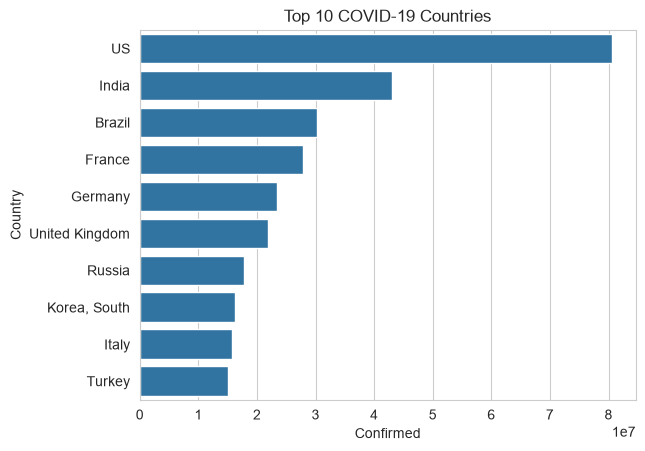

In [6]:
sns.barplot(
    data=country_data.head(10),
    x="Confirmed",
    y="Country"
)

plt.title("Top 10 COVID-19 Countries")
plt.show()

In [7]:
print("Total Countries:", latest["Country"].nunique())
print("Global Confirmed:", latest["Confirmed"].sum())
print("Global Deaths:", latest["Deaths"].sum())
print("Global Recovered:", latest["Recovered"].sum())

print("COVID-19 Analysis Completed!")

Total Countries: 198
Global Confirmed: 504155459
Global Deaths: 6197159
Global Recovered: 0
COVID-19 Analysis Completed!


In [8]:
data.to_csv("COVID_19_Analysis.csv", index=False)

print("COVID-19 CSV File Saved Successfully!")

COVID-19 CSV File Saved Successfully!
